# STA 556 — Homework 4
## Simulation & Resampling
## Samuel Anoff Addo

IMPORTING LIBRARIES, SETTING SEED AND CREATING RANDOM GENERATOR

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

SEED = 556

PART ONE - MONTE CARLO PROBABILITY

TASK: Estimate one probability by simulation with at least 10,000 draws, report it, compare it with the true value, and explain Monte Carlo error.

In [2]:
## Creating Random Number Generator
rng = np.random.default_rng(SEED)

In [3]:
## Estimating Probability that a standard Normal random variable exceeds 1.645
##P(Z > 1.645).

M = 100_000
z = rng.normal(loc = 0, scale = 1, size = M)
indicator = (z > 1.645) 
p_hat = indicator.mean()

In [4]:
print(f"Estimated Probability : {p_hat:.5f}")

Estimated Probability : 0.05015


In [5]:
## Monte Carlo standard error
g = indicator.astype(int)                      # 0/1 values
mcse = g.std(ddof=1) / np.sqrt(len(g))

In [6]:
print(f"MCSE  : {mcse:.5f}")

MCSE  : 0.00069


In [7]:
## Comparing With Available Theoretical Value
Prob_True = 0.05
print(f"Theoretical Probability : {Prob_True:.5f}")
print(f"Absolute error : {abs(p_hat - Prob_True):.5f}")

Theoretical Probability : 0.05000
Absolute error : 0.00015


PART ONE:

Simulations used: 100,000.

Estimate: An estimate of P(Z > 1.645), where Z ~ Normal(0, 1), by simulation. This is the area under the standard normal curve to the right of 1.645.

Comparison With Theory: The theoretical probability is `0.05`. The estimate differs by `0.00015`, with a Monte Carlo Standard Error of `0.00069`.

**Result.**

| Quantity | Value |
|---|---|
| Monte Carlo estimate | 0.05015 |
| Monte Carlo standard error | 0.00069 |
| Exact value| 0.05 |
| Absolute error | 0.00015 |

**Monte Carlo error.** The estimate is itself random because it is based on a finite number of random draws; a different seed would give a slightly different value. The Monte Carlo standard error is computed as the sample standard deviation of the simulated 0s and 1s values divided by the square root of M. It measures the uncertainty in the estimate caused by using a finite number of simulations. It shrinks roughly like 1/sqrt(M) thus one divided by square root of M, so reducing the error by a factor of 10 requires about 100 times as many simulations.

PART TWO — MONTE CARLO STABILITY

TASK: Repeat your Part 1 estimate at several simulation sizes, show a table or plot of how the estimate stabilizes, and explain why more simulations help.

In [8]:
## Simulation Sizes
sizes = [100_000 , 100 , 1_000, 10_000]
p_true = 0.05

## Creating Random Number Generator
rng = np.random.default_rng(SEED)

In [9]:
MonteCarlo = []
for m in sizes:
    z = rng.normal(loc=0, scale=1, size=m)
    g = (z > 1.645).astype(int)

    estimate = g.mean()
    mcse = g.std(ddof=1) / np.sqrt(len(g))

    MonteCarlo.append({
        "Simulation_Size": m,
        "Estimate": estimate,
        "MCSE": mcse,
        "Absolute_Error": abs(estimate - p_true),
    })

In [10]:
MonteCarlo_df = pd.DataFrame(MonteCarlo)
print(f"Exact value: {p_true:.5f}")
MonteCarlo_df

Exact value: 0.05000


,Simulation_Size,Estimate,MCSE,Absolute_Error
0,100000,0.05015,0.000690,0.00015
1,100,0.05000,0.021904,0.00000
2,1000,0.04900,0.006830,0.00100
3,10000,0.05460,0.002272,0.00460


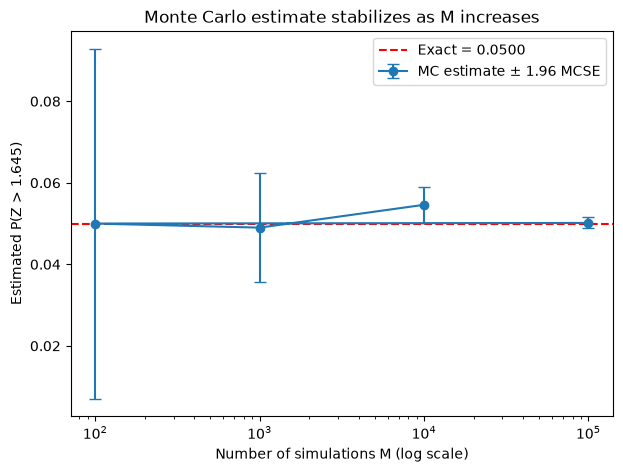

In [11]:
fig, ax = plt.subplots(figsize=(7, 5))

ax.errorbar(MonteCarlo_df["Simulation_Size"], MonteCarlo_df["Estimate"],
            yerr=1.96 * MonteCarlo_df["MCSE"],
            fmt="o-", capsize=4, label="MC estimate ± 1.96 MCSE")
ax.axhline(p_true, color="red", linestyle="--", label=f"Exact = {p_true:.4f}")

ax.set_xscale("log")
ax.set_xlabel("Number of simulations M (log scale)")
ax.set_ylabel("Estimated P(Z > 1.645)")
ax.set_title("Monte Carlo estimate stabilizes as M increases")
ax.legend()
plt.show()

PART TWO:
A Monte Carlo simulation is conducted to estimate P(Z > 1.645) with M = 100, 1,000, 10,000, and 100,000 simulations, using one random number generator throughout. A single random number generator is used throughout the simulations, and the resulting estimates are compared with the exact probability of 0.05.

| M | Estimate | MCSE | Absolute error |
|---|---|---|---|
| 100 | 0.05000 | 0.02190 | 0.00000 |
| 1,000 | 0.04900 | 0.00683 | 0.00100 |
| 10,000 | 0.05460 | 0.00227 | 0.00460 |
| 100,000 | 0.05015 | 0.00069 | 0.00015 |

**Results.** All four estimates are close to `0.05`. The Monte Carlo standard error falls from `0.0219` at M = 100 to `0.00069` at M = 100,000, dropping by a factor of about 3 for each tenfold increase in M, consistent with the 1/sqrt(M) rule.


**Why More Simulations Help:** Increasing the number of simulations improves the reliability of Monte Carlo estimates because it reduces random variation in the results. According to the Law of Large Numbers, as the number of simulations M increases, the sample average tends to get closer to the true expected value. A Monte Carlo estimate is an average of simulated values, so its error comes from random variation in the simulated draws. Averaging over more draws cancels more of the variations making the estimate more stable, and the standard error reduces roughly by 1/sqrt(M)
Therefore, reducing the Monte Carlo standard error by a factor of 10 requires approximately 100 times as many simulations.